In [1]:
import warnings
import matplotlib.pyplot as plt 
import numpy as np 
import pandas as pd 
import seaborn as sns 
from scipy import stats
import dataframe_image as dfi
warnings.filterwarnings("ignore")

In [2]:
# Загрузка данных
users_df = pd.read_csv('ab_test_users_groups.csv')
events_df = pd.read_csv('ab_test_events.csv')

# Вывод размеров таблиц
print("=== РАЗМЕРЫ ДАТАФРЕЙМОВ ===")
print(f"Пользователи и группы (users_df): строк - {users_df.shape[0]}, колонок - {users_df.shape[1]}")
print(f"Логи событий (events_df): строк - {events_df.shape[0]}, колонок - {events_df.shape[1]}\n")

# Первые строки таблицы пользователей
print("=== ПЕРВЫЕ СТРОКИ: users_df ===")
print(users_df.head(), "\n")

# Первые строки таблицы событий
print("=== ПЕРВЫЕ СТРОКИ: events_df ===")
print(events_df.head(), "\n")

# Общая информация о типах данных и пропусках
print("=== ИНФОРМАЦИЯ О ТИПАХ ДАННЫХ И ПРОПУСКАХ ===")
print("--- users_df ---")
print(users_df.info(), "\n")
print("--- events_df ---")
print(events_df.info())

=== РАЗМЕРЫ ДАТАФРЕЙМОВ ===
Пользователи и группы (users_df): строк - 6008, колонок - 4
Логи событий (events_df): строк - 179330, колонок - 3

=== ПЕРВЫЕ СТРОКИ: users_df ===
   user_id group signup_date  grade
0  U300000     B  2026-03-09      5
1  U300001     B  2025-09-07      9
2  U300002     B  2026-01-11      9
3  U300003     A  2025-06-07      5
4  U300004     B  2025-12-25     11 

=== ПЕРВЫЕ СТРОКИ: events_df ===
   user_id            timestamp          event_type
0  U300281  2026-05-04 00:06:44  homework_completed
1  U300733  2026-05-04 00:19:56  homework_completed
2  U304499  2026-05-04 00:22:07               login
3  U304266  2026-05-04 00:23:42    homework_started
4  U304266  2026-05-04 00:23:42    homework_started 

=== ИНФОРМАЦИЯ О ТИПАХ ДАННЫХ И ПРОПУСКАХ ===
--- users_df ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6008 entries, 0 to 6007
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   user

NULL в таблицах нет, поэтому пропуски заполнять не нужно.

In [4]:
# Список всех уникальных событий и их количество в датасете
print("=== УНИКАЛЬНЫЕ СОБЫТИЯ И ИХ КОЛИЧЕСТВО ===")
print(events_df['event_type'].value_counts(dropna=False))

=== УНИКАЛЬНЫЕ СОБЫТИЯ И ИХ КОЛИЧЕСТВО ===
event_type
login                 75552
homework_started      68317
homework_completed    28995
return_visit_d7        4519
return_visit_d14       1947
Name: count, dtype: int64


1. Подготовим данные

In [6]:
# Преобразуем timestamp в формат datetime
events_df['timestamp'] = pd.to_datetime(events_df['timestamp'])
print("Преобразование дат завершено ")

Преобразование дат завершено 


In [7]:
# Удаленим дубликатов
# Проверяем количество полных дубликатов
users_duplicates = users_df.duplicated().sum()
events_duplicates = events_df.duplicated().sum()

print("=== КОЛИЧЕСТВО ДУБЛИКАТОВ ===")
print(f"В users_df: {users_duplicates} строк")
print(f"В events_df: {events_duplicates} строк\n")

# Удаляем дубликаты, если они есть
if users_duplicates > 0:
    users_df = users_df.drop_duplicates().reset_index(drop=True)
    print("Дубликаты из users_df успешно удалены.")

if events_duplicates > 0:
    events_df = events_df.drop_duplicates().reset_index(drop=True)
    print("Дубликаты из events_df успешно удалены.")

# Проверяем итоговый размер таблиц
print("\n=== НОВЫЕ РАЗМЕРЫ ТАБЛИЦ ===")
print(f"users_df: {users_df.shape[0]} строк")
print(f"events_df: {events_df.shape[0]} строк")

=== КОЛИЧЕСТВО ДУБЛИКАТОВ ===
В users_df: 0 строк
В events_df: 2 строк

Дубликаты из events_df успешно удалены.

=== НОВЫЕ РАЗМЕРЫ ТАБЛИЦ ===
users_df: 6008 строк
events_df: 179328 строк


In [8]:
# Проверим нет ли пользователей, которые присутствуют только в одной из таблиц

# Множества уникальных user_id из обеих таблиц
users_id_set = set(users_df['user_id'])
events_id_set = set(events_df['user_id'])

# Пересечение и расхождения
only_in_users = users_id_set - events_id_set
only_in_events = events_id_set - users_id_set
in_both = users_id_set.intersection(events_id_set)

print("=== СВЕРКА ПОЛЬЗОВАТЕЛЕЙ ПО ТАБЛИЦАМ ===")
print(f"Всего уникальных пользователей в users_df: {len(users_id_set)}")
print(f"Всего уникальных пользователей в events_df: {len(events_id_set)}")
print(f"Пользователей, присутствующих в обеих таблицах: {len(in_both)}")
print(f"Пользователей ЕСТЬ в users_df, но НЕТ в событиях: {len(only_in_users)}")
print(f"Пользователей ЕСТЬ в событиях, но НЕТ в users_df (призраки): {len(only_in_events)}")

=== СВЕРКА ПОЛЬЗОВАТЕЛЕЙ ПО ТАБЛИЦАМ ===
Всего уникальных пользователей в users_df: 6000
Всего уникальных пользователей в events_df: 6000
Пользователей, присутствующих в обеих таблицах: 6000
Пользователей ЕСТЬ в users_df, но НЕТ в событиях: 0
Пользователей ЕСТЬ в событиях, но НЕТ в users_df (призраки): 0


In [9]:
# Проверим временные рамки эксперимента (должны быть 3 недели)

print("\n=== ВРЕМЕННЫЕ РАМКИ ЭКСПЕРИМЕНТА ===")
print(f"Минимальная дата (старт): {events_df['timestamp'].min()}")
print(f"Максимальная дата (конец): {events_df['timestamp'].max()}")



=== ВРЕМЕННЫЕ РАМКИ ЭКСПЕРИМЕНТА ===
Минимальная дата (старт): 2026-05-04 00:06:44
Максимальная дата (конец): 2026-05-24 23:55:43


Диапозон дат в таблице events_df действительно составляет 3 недели

2. Проведем sanity check

In [12]:
# Считаем, в скольких группах состоит каждый пользователь
user_group_counts = users_df.groupby('user_id')['group'].nunique()

# Находим ID пользователей, которые попали более чем в 1 группу (если есть)
double_group_users = user_group_counts[user_group_counts > 1].index.tolist()

print("=== ПРОВЕРКА ПЕРЕСЕЧЕНИЯ ГРУПП ===")
print(f"Количество пользователей, попавших в обе группы (A и B): {len(double_group_users)}")

# Если такие пользователи есть — удаляем их из обеих таблиц
if len(double_group_users) > 0:
    # Удаляем из users_df
    users_df = users_df[~users_df['user_id'].isin(double_group_users)].reset_index(drop=True)
    # Удаляем из events_df
    events_df = events_df[~events_df['user_id'].isin(double_group_users)].reset_index(drop=True)
    
    print(f"Пользователи с двойной группой успешно удалены из users_df и events_df.")
    print(f"Осталось пользователей в users_df: {users_df['user_id'].nunique()}")
else:
    print("Отлично! Пересечений между группами не обнаружено.")

=== ПРОВЕРКА ПЕРЕСЕЧЕНИЯ ГРУПП ===
Количество пользователей, попавших в обе группы (A и B): 8
Пользователи с двойной группой успешно удалены из users_df и events_df.
Осталось пользователей в users_df: 5992


Будем использовать критерий Хи-квадрат, т. к.  
* Данные, которые мы анализируем (доля пользователей в каждой из групп) - бинарные  
* Выборки имеют большой размер

Обозначим через d_A и d_B доли пользователей в группах A и B соответственно.  
Нулевая гипотеза H0: доля пользователей в группе A равна доле пользователей в группе B (d_A = d_B = 0.5).  
Альтернативная гипотеза H1: доля пользователей в группе A не равна доле пользователей в группе B (d_A <> d_B).  
Уровень занчимости alpha = 0.05.

In [14]:
from scipy.stats import chisquare

# Считаем фактическое количество пользователей в каждой группе
group_counts = users_df['group'].value_counts()
observed = [group_counts['A'], group_counts['B']]
total_users = sum(observed)

# Формируем ожидаемое количество пользователей при идеальном сплите 50/50
expected = [total_users / 2, total_users / 2]

# Применяем критерий Хи-квадрат
chi2_stat, p_value = chisquare(f_obs=observed, f_exp=expected)

# Вывод результатов
alpha = 0.05

print("=== ПРОВЕРКА РАВНОМЕРНОСТИ СПЛИТОВАНИЯ (SRM TEST) ===")
print(f"Фактическое кол-во пользователей в группе A: {observed[0]} ({observed[0]/total_users:.2%})")
print(f"Фактическое кол-во пользователей в группе B: {observed[1]} ({observed[1]/total_users:.2%})")
print(f"Значение статистики Хи-квадрат: {chi2_stat:.4f}")
print(f"p-value: {p_value:.6f}\n")

# 5. Интерпретация результата
if p_value < alpha:
    print(f"ОТКЛОНЯЕМ H0 (p-value < {alpha}): Обнаружен статистически значимый дисбаланс выборок (SRM)!")
    print("Сплитование прошло некорректно, группы несопоставимы по размеру.")
else:
    print(f"НЕ ОТКЛОНЯЕМ H0 (p-value >= {alpha}): Проблема SRM не обнаружена.")
    print("Распределение пользователей между группами A и B соответствует 50/50.")

=== ПРОВЕРКА РАВНОМЕРНОСТИ СПЛИТОВАНИЯ (SRM TEST) ===
Фактическое кол-во пользователей в группе A: 2997 (50.02%)
Фактическое кол-во пользователей в группе B: 2995 (49.98%)
Значение статистики Хи-квадрат: 0.0007
p-value: 0.979387

НЕ ОТКЛОНЯЕМ H0 (p-value >= 0.05): Проблема SRM не обнаружена.
Распределение пользователей между группами A и B соответствует 50/50.


3. Проверим данные на ботов (аномально активных пользователей)

In [16]:
# Агрегируем данные по пользователям на основе events_df
user_activity = events_df.groupby('user_id').agg(
    events_count=('event_type', 'count'),
    unique_event_types=('event_type', 'nunique'),
    first_event=('timestamp', 'min'),
    last_event=('timestamp', 'max')
).reset_index()

# Рассчитываем продолжительность сессии в часах
duration_seconds = (user_activity['last_event'] - user_activity['first_event']).dt.total_seconds()
user_activity['duration_hours'] = duration_seconds / 3600.0

display(
    user_activity
    .sort_values("events_count", ascending=False)
    .head(20)
)

,user_id,events_count,unique_event_types,first_event,last_event,duration_hours
3722,U303729,842,4,2026-05-04 00:28:33,2026-05-24 23:35:32,503.116389
4160,U304167,829,4,2026-05-04 02:10:48,2026-05-24 23:39:23,501.476389
5370,U305378,793,5,2026-05-04 01:03:47,2026-05-24 21:53:58,500.836389
2833,U302840,790,3,2026-05-04 00:33:05,2026-05-24 23:23:41,502.843333
4259,U304266,780,4,2026-05-04 00:23:42,2026-05-24 22:44:27,502.345833
571,U300573,771,4,2026-05-04 00:25:53,2026-05-24 23:55:18,503.490278
731,U300733,770,4,2026-05-04 00:19:56,2026-05-24 23:16:13,502.938056
2372,U302379,765,4,2026-05-04 01:05:22,2026-05-24 23:35:37,502.504167
281,U300281,760,4,2026-05-04 00:06:44,2026-05-24 23:42:11,503.590833
158,U300158,738,4,2026-05-04 01:26:49,2026-05-24 18:36:44,497.165278


Видим, что чем больше действий совершил пользователь, тем больше времени он потратил на курс.   
Пока нет никаких видимых признаков ботов.

In [18]:
 # деятельность самых активных пользователей
suspicious_users = (
    user_activity
    .nlargest(10, "events_count")["user_id"]
    .tolist()
)
# Все события этих пользователей
display(events_df[
    events_df["user_id"].isin(suspicious_users)
].sort_values(["user_id", "timestamp"]).head(10))

,user_id,timestamp,event_type
20,U300158,2026-05-04 01:26:49,homework_completed
23,U300158,2026-05-04 01:39:18,homework_completed
32,U300158,2026-05-04 02:15:16,homework_started
36,U300158,2026-05-04 02:28:59,homework_completed
37,U300158,2026-05-04 02:45:49,homework_started
49,U300158,2026-05-04 03:26:16,homework_started
79,U300158,2026-05-04 04:57:18,homework_completed
80,U300158,2026-05-04 05:01:00,login
81,U300158,2026-05-04 05:03:19,login
121,U300158,2026-05-04 07:48:42,homework_completed


Видим, что у некоторых пользователей event_type homework_completed идет раньше чем login. Вот это точно неправильно. Такие пользователи должны быть удалены. Так же должны быть удалены те пользователи, которые завершили домашнее задание, до того как начали его (homework_completed идет раньше чем homework_started), и те пользователи, у которых event_type homework_started идет раньше чем login.

In [20]:
# Объединяем таблицы
df_merged = pd.merge(events_df, users_df, on="user_id", how="left")
df_merged["event_date"] = df_merged["timestamp"].dt.date

# Находим время ПЕРВОГО события каждого типа для каждого пользователя
first_events = df_merged.groupby(['user_id', 'event_type'])['timestamp'].min().unstack()

# Заполняем отсутствующие события очень поздней датой, чтобы сравнения не ломались 
# (но только для расчетов внутри этого блока)
far_future = pd.to_datetime("2099-01-01")
check_df = first_events.fillna(far_future)

# 1 аномалия: Любое действие с ДЗ до login (homework_started < login) ИЛИ (homework_completed < login)
anomaly_before_login = check_df[
    (check_df ['homework_started'] < check_df['login']) | (check_df['homework_completed'] < check_df['login'])
].index.tolist()
# 2 аномалия: Завершил раньше, чем начал (если оба события есть) # (completed < started) - проверяем только тех, кто реально совершил оба действия
anomaly_wrong_order = check_df[
    (check_df ['homework_completed'] < check_df['homework_started' ]) & (check_df['homework_started'] != far_future) & (check_df ['homework_completed'] != far_future)
].index.tolist()
print(f"Пользователей, совершивших действия с ДЗ до логина: {len(anomaly_before_login)}")
print(f"Пользователей, завершивших ДЗ раньше, чем начали его: {len(anomaly_wrong_order)}")

# Объединяем всех подозрительных пользователей в один список
all_suspicious_users = list(set(anomaly_before_login + anomaly_wrong_order))
if len (all_suspicious_users) > 0:
    users_df = users_df[~users_df['user_id'].isin(all_suspicious_users)]
    events_df = events_df[~events_df['user_id'].isin(all_suspicious_users)]
    print(f"Итого удалено 'нелогичных' пользователей: {len(all_suspicious_users)}")
    # Пересобираем merged
    df_merged = pd.merge(events_df, users_df, on="user_id", how="inner")
else:
    print("Критичных нарушений логики событий не обнаружено.")
print (f"Итоговое кол-во пользователей в анализе: {df_merged['user_id'].nunique()}")

Пользователей, совершивших действия с ДЗ до логина: 8
Пользователей, завершивших ДЗ раньше, чем начали его: 7
Итого удалено 'нелогичных' пользователей: 11
Итоговое кол-во пользователей в анализе: 5981


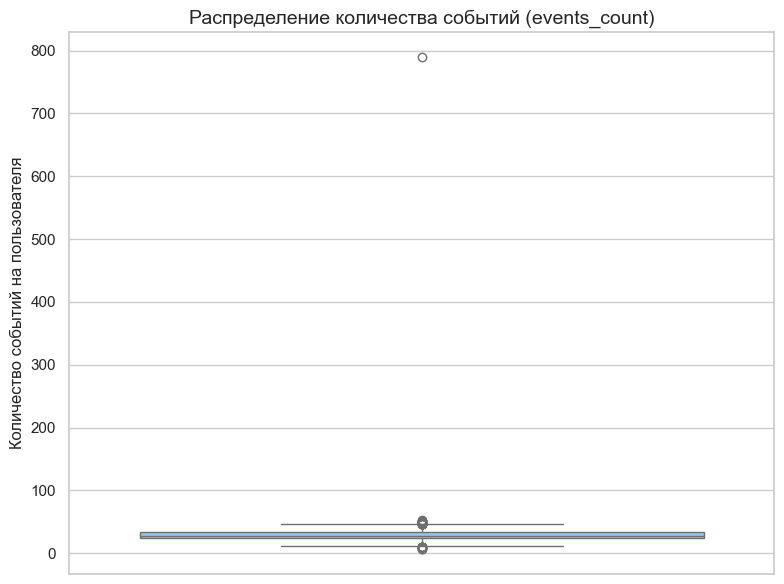

In [21]:
# Визуализируем данные для выявления аномалий

# Фильтруем user_activity, оставляя только актуальных пользователей
user_act_clean = user_activity[user_activity['user_id'].isin(users_df['user_id'])].copy()

# Настройка стилей
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(8, 6))

# Boxplot для Количество событий на пользователя (events_count)
sns.boxplot(y=user_act_clean['events_count'], ax=ax, color='skyblue')
ax.set_title('Распределение количества событий (events_count)', fontsize=14)
ax.set_ylabel('Количество событий на пользователя', fontsize=12)

plt.tight_layout()
plt.show()

In [22]:
# Вывод числовых показателей перцентилей для определения порога аномалий
print("=== КЛЮЧЕВЫЕ КВАНТИЛИ ДЛЯ ВЫЯВЛЕНИЯ ВЫБРОСОВ ===")
print("events_count (события):")
print(user_act_clean['events_count'].quantile([0.5, 0.90, 0.95, 0.99, 0.999]))


=== КЛЮЧЕВЫЕ КВАНТИЛИ ДЛЯ ВЫЯВЛЕНИЯ ВЫБРОСОВ ===
events_count (события):
0.500    28.0
0.900    37.0
0.950    40.0
0.990    45.0
0.999    49.0
Name: events_count, dtype: float64


In [23]:
# Расчет математического порога по методу IQR (Межквартильный размах)

user_act_clean = user_activity[user_activity['user_id'].isin(users_df['user_id'])].copy()
q1 = user_act_clean['events_count'].quantile(0.25)
q3 = user_act_clean['events_count'].quantile (0.75)
iqr = q3 - q1
upper_bound_1_5 = q3 + 1.5 * iqr
outliers_1_5_count = (user_act_clean['events_count'] > upper_bound_1_5).sum()
print ("=== РАСЧЕТ IQR ДЛЯ events_count ===")
print (f"25-й процентиль (Q1): {q1}") 
print (f"75-й процентиль (Q3): {q3}") 
print (f"Межквартильный размах (IQR): {iqr}")
print(f"Верхняя граница (Q3 + 1.5 * IQR): {upper_bound_1_5:.2f}")
print (f"Количество пользователей выше порога 1.5*IQR: {outliers_1_5_count} ( из {len(user_act_clean)})")

=== РАСЧЕТ IQR ДЛЯ events_count ===
25-й процентиль (Q1): 24.0
75-й процентиль (Q3): 33.0
Межквартильный размах (IQR): 9.0
Верхняя граница (Q3 + 1.5 * IQR): 46.50
Количество пользователей выше порога 1.5*IQR: 31 ( из 5981)


ИТОГ: большая часть учеников (99,5%) совершает не более 50 событий. Из этого следует, что ученики которые совершают больше 50 событий, являются ботами. Их так же следует удалить.

In [25]:
# Находим user_id пользователей, совершивших больше 50 событий
bots_by_events = user_act_clean[user_act_clean['events_count'] > 50]['user_id'].tolist()

print("=== УДАЛЕНИЕ ПОЛЬЗОВАТЕЛЕЙ С > 50 СОБЫТИЙ ===")
print(f"Количество найденных аномальных пользователей (ботов): {len(bots_by_events)}")

# Фильтруем основные датафреймы
users_df = users_df[~users_df['user_id'].isin(bots_by_events)].reset_index(drop=True)
events_df = events_df[~events_df['user_id'].isin(bots_by_events)].reset_index(drop=True)

# Обновляем объединенную таблицу df_merged
df_merged = pd.merge(events_df, users_df, on="user_id", how="inner")

# Проверяем итоговое количество чистых пользователей
print(f"Пользователей осталось в users_df: {users_df['user_id'].nunique()}")
print(f"Пользователей осталось в events_df: {events_df['user_id'].nunique()}")
print(f"Размер итогового df_merged: {df_merged.shape[0]} строк")

=== УДАЛЕНИЕ ПОЛЬЗОВАТЕЛЕЙ С > 50 СОБЫТИЙ ===
Количество найденных аномальных пользователей (ботов): 4
Пользователей осталось в users_df: 5977
Пользователей осталось в events_df: 5977
Размер итогового df_merged: 169679 строк


Переходим к решениию задачи 

4. Рассчитаем метрики

In [28]:
# Completion Rate

# Находим уникальных пользователей, у которых есть хотя бы одно событие 'homework_completed'
completed_users = df_merged[df_merged['event_type'] == 'homework_completed']['user_id'].unique()

# Добавляем бинарный флаг прохождения (1 - завершил, 0 - не завершил) в users_df
users_df['is_completed'] = users_df['user_id'].isin(completed_users).astype(int)

# Считаем Completion Rate для каждой группы
cr_summary = users_df.groupby('group').agg(
    total_users=('user_id', 'count'),
    completed_users=('is_completed', 'sum'),
    completion_rate=('is_completed', 'mean')
).reset_index()

# Форматируем в проценты
cr_summary['cr_percent'] = (cr_summary['completion_rate'] * 100).round(2)

print("=== COMPLETION RATE ПО ГРУППАМ ===")
print(cr_summary.to_string(index=False))

=== COMPLETION RATE ПО ГРУППАМ ===
group  total_users  completed_users  completion_rate  cr_percent
    A         2992             2921         0.976270       97.63
    B         2985             2950         0.988275       98.83


ЗАМЕЧАНИЕ: Из-за отсутствия флага о завершения курса (`course_completed`), метрика Completion Rate рассчитана по целевому действию — успешному выполнению домашних заданий (`homework_completed`)

In [31]:
# Retention Rate 7D u 14D

# Находим пользователей с событиями возврата
retention_7d_users = df_merged[df_merged['event_type'] == 'return_visit_d7']['user_id'].unique()
retention_14d_users = df_merged[df_merged['event_type'] == 'return_visit_d14']['user_id'].unique()

# Присваиваем флаги возврата в users_df
users_df['retention_7d'] = users_df['user_id'].isin(retention_7d_users).astype(int)
users_df['retention_14d'] = users_df['user_id'].isin(retention_14d_users).astype(int)

# Таблица для Retention 7D
retention_7d_df = users_df.groupby('group').agg(
    total_users=('user_id', 'count'),
    returned_users=('retention_7d', 'sum'),
    retention_rate=('retention_7d', 'mean')
).reset_index()

retention_7d_df['retention_rate'] = (retention_7d_df['retention_rate'] * 100).round(2).astype(str) + '%'

# Таблица для Retention 14D
retention_14d_df = users_df.groupby('group').agg(
    total_users=('user_id', 'count'),
    returned_users=('retention_14d', 'sum'),
    retention_rate=('retention_14d', 'mean')
).reset_index()

retention_14d_df['retention_rate'] = (retention_14d_df['retention_rate'] * 100).round(2).astype(str) + '%'

# Вывод результатов
print("=== RETENTION RATE 7D ===")
print(retention_7d_df.to_string(index=False))

print("\n=== RETENTION RATE 14D ===")
print(retention_14d_df.to_string(index=False))

=== RETENTION RATE 7D ===
group  total_users  returned_users retention_rate
    A         2992            2175         72.69%
    B         2985            2327         77.96%

=== RETENTION RATE 14D ===
group  total_users  returned_users retention_rate
    A         2992             862         28.81%
    B         2985            1082         36.25%


In [32]:
# Воронка

# Задаем шаги воронки
funnel_steps = ['login', 'homework_started', 'homework_completed']

# Функция для создания таблицы воронки по группе
def create_funnel_table(group_name):
    data = []
    
    # Общее число пользователей, совершивших вход (первый шаг)
    first_step_users = df_merged[(df_merged['group'] == group_name) & (df_merged['event_type'] == 'login')]['user_id'].nunique()
    
    prev_users = first_step_users
    
    for step in funnel_steps:
        users_count = df_merged[(df_merged['group'] == group_name) & (df_merged['event_type'] == step)]['user_id'].nunique()
        
        # Расчет конверсий
        conv_first = (users_count / first_step_users * 100) if first_step_users > 0 else 0
        conv_prev = (users_count / prev_users * 100) if prev_users > 0 else 0
        
        data.append({
            'step': step,
            'user_count': users_count,
            'conversion_to_first_step': f"{conv_first:.2f}%",
            'conversion_to_prev_step': f"{conv_prev:.2f}%"
        })
        
        prev_users = users_count
        
    return pd.DataFrame(data)

# Генерируем таблицы для обеих групп
funnel_A = create_funnel_table('A')
funnel_B = create_funnel_table('B')

# Вывод результатов
print("=== ВОРОНКА КОНВЕРСИИ: ГРУППА A (Контроль) ===")
print(funnel_A.to_string(index=False))

print("\n=== ВОРОНКА КОНВЕРСИИ: ГРУППА B (Тест — Геймификация) ===")
print(funnel_B.to_string(index=False))

=== ВОРОНКА КОНВЕРСИИ: ГРУППА A (Контроль) ===
              step  user_count conversion_to_first_step conversion_to_prev_step
             login        2992                  100.00%                 100.00%
  homework_started        2992                  100.00%                 100.00%
homework_completed        2921                   97.63%                  97.63%

=== ВОРОНКА КОНВЕРСИИ: ГРУППА B (Тест — Геймификация) ===
              step  user_count conversion_to_first_step conversion_to_prev_step
             login        2985                  100.00%                 100.00%
  homework_started        2985                  100.00%                 100.00%
homework_completed        2950                   98.83%                  98.83%


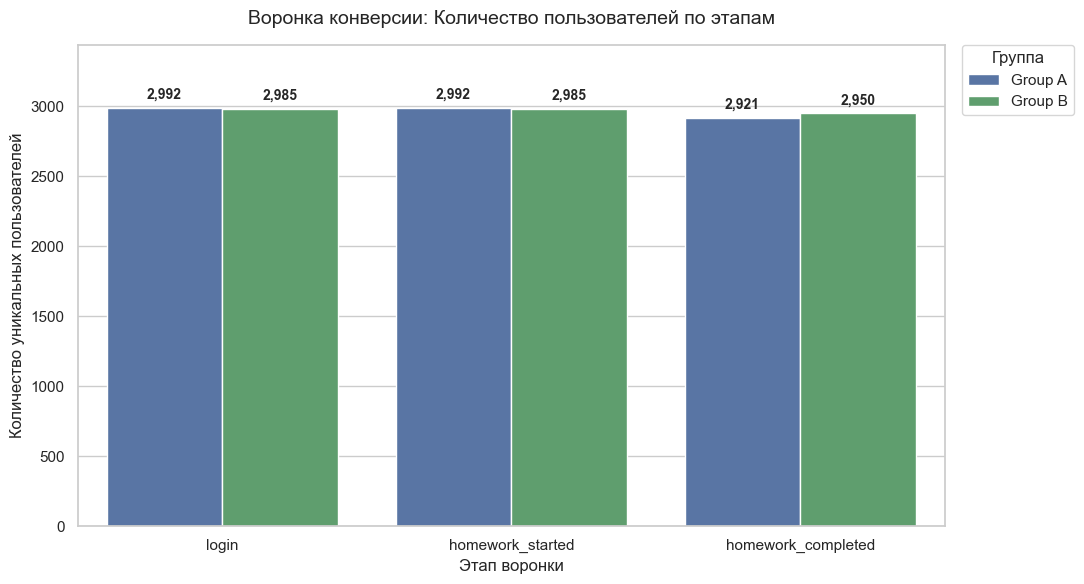

In [33]:
# Визуализация воронки

# Подготовка данных по количеству пользователей
funnel_steps = ['login', 'homework_started', 'homework_completed']
funnel_counts = []

for group in ['A', 'B']:
    for step in funnel_steps:
        cnt = df_merged[(df_merged['group'] == group) & (df_merged['event_type'] == step)]['user_id'].nunique()
        funnel_counts.append({'group': f'Group {group}', 'step': step, 'user_count': cnt})

funnel_counts_df = pd.DataFrame(funnel_counts)

# Построение графика
plt.figure(figsize=(11, 6))
sns.set_theme(style="whitegrid")

ax = sns.barplot(
    x='step', 
    y='user_count', 
    hue='group', 
    data=funnel_counts_df, 
    palette=['#4C72B0', '#55A868']
)

# Настройка подписей и осей
plt.title('Воронка конверсии: Количество пользователей по этапам', fontsize=14, pad=15)
plt.xlabel('Этап воронки', fontsize=12)
plt.ylabel('Количество уникальных пользователей', fontsize=12)
plt.ylim(0, funnel_counts_df['user_count'].max() * 1.15)

# Вывод точного количества пользователей над столбиками
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{int(height):,}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom',
                    fontsize=10, fontweight='bold', xytext=(0, 4),
                    textcoords='offset points')

# Выносим легенду ЗА ПРЕДЕЛЫ графика справа
plt.legend(title='Группа', bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)

plt.tight_layout()
plt.show()

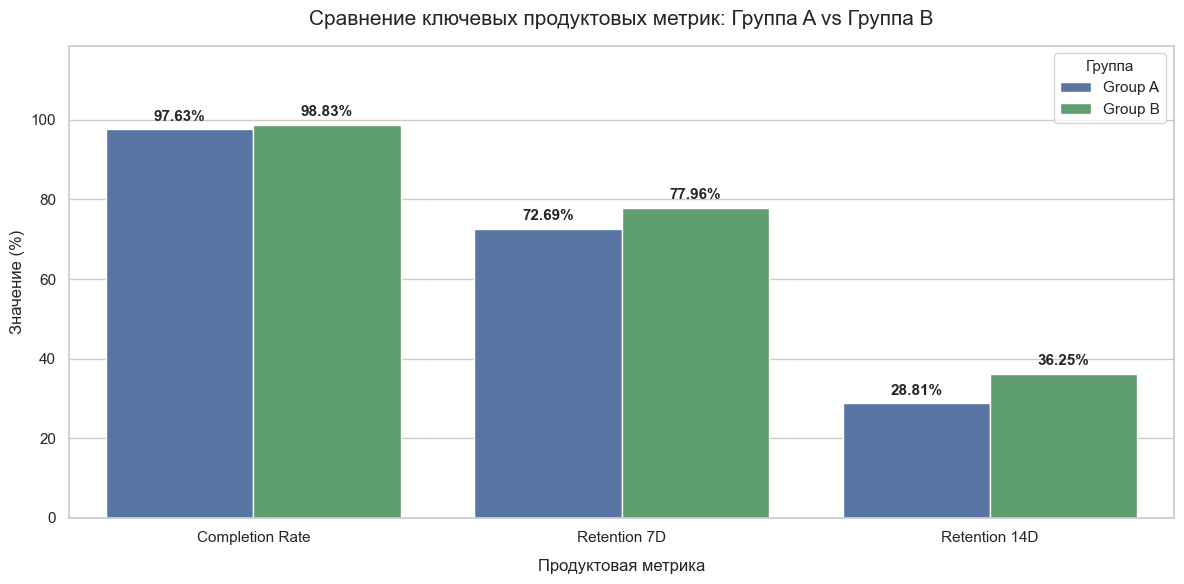

In [34]:
# Визуализация полученных результатов

# Подготовка данных для визуализации
metrics_data = pd.DataFrame({
    'Metric': ['Completion Rate', 'Retention 7D', 'Retention 14D', 
               'Completion Rate', 'Retention 7D', 'Retention 14D'],
    'Group': ['Group A', 'Group A', 'Group A', 
              'Group B', 'Group B', 'Group B'],
    'Value': [
        users_df[users_df['group'] == 'A']['is_completed'].mean() * 100,
        users_df[users_df['group'] == 'A']['retention_7d'].mean() * 100,
        users_df[users_df['group'] == 'A']['retention_14d'].mean() * 100,
        users_df[users_df['group'] == 'B']['is_completed'].mean() * 100,
        users_df[users_df['group'] == 'B']['retention_7d'].mean() * 100,
        users_df[users_df['group'] == 'B']['retention_14d'].mean() * 100
    ]
})

# Настройка стиля и размера графика
plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")

# Строим столбчатую диаграмму
ax = sns.barplot(
    x='Metric', 
    y='Value', 
    hue='Group', 
    data=metrics_data, 
    palette=['#4C72B0', '#55A868'] # Синий для A, Зеленый для B
)

# Настройки заголовков и осей
plt.title('Сравнение ключевых продуктовых метрик: Группа A vs Группа B', fontsize=15, pad=15)
plt.xlabel('Продуктовая метрика', fontsize=12, labelpad=10)
plt.ylabel('Значение (%)', fontsize=12)
plt.ylim(0, max(metrics_data['Value']) * 1.2) # Добавляем запас сверху для подписей

# Добавление точных процентных значений над каждого столбика
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{height:.2f}%',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom',
                    fontsize=11, fontweight='bold', xytext=(0, 4),
                    textcoords='offset points')

plt.legend(title='Группа', title_fontsize='11', loc='upper right')
plt.tight_layout()
plt.show()

6. Выполним статистические расчеты p-value и доверительных интервалов   

Используем Z-тест для сравнения двух пропорций, т. к.:
* данные, которые мы анализируем, категориальные
* размер выборки большой
* этот критерий позволяет легко построить доверительный интервал для разницы пропорций
   
Нулевая гипотеза H0: Доля Retention/Completion Rate в группе А равна доле в группе В (p_A = р_B).   
Альтернативная гипотеза H1: Доля Retention/Completion Rate в группе А не равна доле в группе В (p_A <> р_B).   
Уровень занчимости alpha = 0.05.   

In [37]:
# Функция для Z-теста
def z_test_proportions(successes_A, size_A, successes_B, size_B, alpha=0.05):
    # Выполняет двухвыборочный Z-тест для равенства долей и строит 95% ДИ для их разности.
    P_A = successes_A / size_A
    P_B = successes_B / size_B
    diff = P_B - P_A
    
    # Объединенная пропорция (Pooled proportion) для стандартной ошибки под нулевую гипотезу
    p_pooled = (successes_A + successes_B) / (size_A + size_B)
    se_pooled = np.sqrt(p_pooled * (1 - p_pooled) * (1/size_A + 1/size_B))
    
    # Z-статистика и p-value
    z_stat = diff / se_pooled
    p_value = 2 * (1 - norm.cdf(abs(z_stat)))
    
    # Стандартная ошибка для доверительного интервала (Unpooled)
    se_diff = np.sqrt((P_A * (1 - P_A) / size_A) + (P_B * (1 - P_B) / size_B))
    
    # Квантиль для 95% ДИ
    z_critical = norm.ppf(1 - alpha / 2)
    ci_lower = diff - z_critical * se_diff
    ci_upper = diff + z_critical * se_diff
    
    return {
        'P_A': P_A,
        'P_B': P_B,
        'diff': diff,
        'z_stat': z_stat,
        'p_value': p_value,
        'ci_lower': ci_lower,
        'ci_upper': ci_upper,
        'significant': p_value < alpha
    }

In [38]:
# Метрики для проверки (исправили 'retention 14d' на 'retention_14d')
from scipy. stats import norm

metrics = {
    'Completion Rate': ('is_completed', users_df),
    'Retention Rate 7D': ('retention_7d', users_df),
    'Retention Rate 14D': ('retention_14d', users_df)
}

alpha = 0.05

print("=== РЕЗУЛЬТАТЫ СТАТИСТИЧЕСКОГО ТЕСТИРОВАНИЯ (Z-TEST, alpha = 0.05) ===\n")

for metric_name, (col_name, df) in metrics.items():
    group_A = df[df['group'] == 'A'][col_name]
    group_B = df[df['group'] == 'B'][col_name]
    
    succ_A, size_A = group_A.sum(), len(group_A)
    succ_B, size_B = group_B.sum(), len(group_B)
    
    res = z_test_proportions(succ_A, size_A, succ_B, size_B, alpha)
    
    print(f"--- МЕТРИКА: {metric_name} ---")
    print(f"Группа A: {res['P_A']:.2%} ({succ_A}/{size_A})")
    print(f"Группа B: {res['P_B']:.2%} ({succ_B}/{size_B})")
    print(f"Абсолютный прирост (P_B - P_A): {res['diff']*100:+.2f}%")
    print(f"95% Доверительный интервал разности: [{res['ci_lower']*100:+.2f}%, {res['ci_upper']*100:+.2f}%]")
    print(f"Z-статистика: {res['z_stat']:.4f}")
    print(f"p-value: {res['p_value']:.6f}")
    
    if res['significant']:
        print(f"ВЫВОД: Статистически значимое различие ЕСТЬ (Отклоняем H0, p-value < {alpha})\n")
    else:
        print(f"ВЫВОД: Статистически значимого различия НЕТ (Не отклоняем H0, p-value >= {alpha})\n")

=== РЕЗУЛЬТАТЫ СТАТИСТИЧЕСКОГО ТЕСТИРОВАНИЯ (Z-TEST, alpha = 0.05) ===

--- МЕТРИКА: Completion Rate ---
Группа A: 97.63% (2921/2992)
Группа B: 98.83% (2950/2985)
Абсолютный прирост (P_B - P_A): +1.20%
95% Доверительный интервал разности: [+0.53%, +1.87%]
Z-статистика: 3.5159
p-value: 0.000438
ВЫВОД: Статистически значимое различие ЕСТЬ (Отклоняем H0, p-value < 0.05)

--- МЕТРИКА: Retention Rate 7D ---
Группа A: 72.69% (2175/2992)
Группа B: 77.96% (2327/2985)
Абсолютный прирост (P_B - P_A): +5.26%
95% Доверительный интервал разности: [+3.08%, +7.44%]
Z-статистика: 4.7184
p-value: 0.000002
ВЫВОД: Статистически значимое различие ЕСТЬ (Отклоняем H0, p-value < 0.05)

--- МЕТРИКА: Retention Rate 14D ---
Группа A: 28.81% (862/2992)
Группа B: 36.25% (1082/2985)
Абсолютный прирост (P_B - P_A): +7.44%
95% Доверительный интервал разности: [+5.07%, +9.81%]
Z-статистика: 6.1372
p-value: 0.000000
ВЫВОД: Статистически значимое различие ЕСТЬ (Отклоняем H0, p-value < 0.05)



7. Сформулируем выводы

Общие выводы из статистических тестов:

*   Все три метрики показали статистически значимое улучшение в группе B (с геймификацией) по сравнению с группой A.
*   Наибольший эффект наблюдается в Retention Rate 14D (прирост +25.82%), что говорит о том, что геймификация помогает удерживать пользователей дольше.
*   Retention Rate 7D также показал хороший прирост (+7.24%).
*   Completion Rate показал статистически значимый, но небольшой абсолютный прирост. Относительный прирост +1.23% кажется незначительным, но при высоких базовых значениях (97.63%) даже такое улучшение может быть ценным, если оно статистически значимо.

Оценка практической бизнес-значимости:

*   Retention Rate: Улучшение Retention Rate на 5-7 процентных пунктов (абсолютных) — это очень существенное улучшение для образовательной платформы. Это означает, что больше пользователей возвращается, проходит больше модулей, дольше остаются на платформе. Это прямо ведет к увеличению LTV (Lifetime Value) пользователя и снижению стоимости привлечения следующего клиента (так как существующие остаются дольше).
*   Completion Rate: Прирост Completion Rate, хотя и небольшой в абсолютном выражении (+1.20 п.п.), но статистически значимый. Важно учесть, что базовый Completion Rate уже очень высок (97.63%), поэтому достичь большого абсолютного прироста сложно. Даже такое небольшое улучшение, когда почти все пользователи и так завершают курс, может быть ценным

Рекомендация для продуктовой команды:

**На основе полученных результатов, рекомендуется РАСКАТИТЬ новую механику геймификации (систему достижений) на всех пользователей.**

Обоснование:

1.  Статистическая значимость: Все ключевые метрики — Retention 7D, Retention 14D и Completion Rate — показали статистически значимое положительное изменение в группе с геймификацией.
2.  Положительный эффект на удержание: Наибольший и наиболее впечатляющий эффект наблюдается в метриках удержания (Retention Rate 7D и особенно 14D). Это указывает на то, что геймификация действительно делает пользователей более вовлеченными и склонными возвращаться на платформу.
3.  Положительный эффект на Completion Rate: Несмотря на небольшой абсолютный прирост, он статистически значим. Учитывая, что геймификация нацелена на повышение мотивации за счет достижений, это естественный эффект.
4.  Практическая значимость: Улучшение Retention Rate на 5-7 процентных пунктов (абсолютных) на 14-й день — это очень сильный результат, который напрямую влияет на ключевые бизнес-показатели, такие как LTV и удовлетворенность пользователей.
5.  Отсутствие негативных эффектов: Тесты не выявили негативного влияния геймификации на другие метрики.